In [ ]:
import os
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_in = os.path.join(pth, 'data', 'development', 'mesencoder')
# pth_out = os.path.join(pth, 'figures', 'mesencoder', 'embedding')
# pth_cb = os.path.join(pth_out, 'colorbars')

In [3]:
celltypes = [
    'Epiblast',
    'Posterior Epiblast',
    'Lateral Plate Mesoderm',
    'Neuromesodermal Progenitor',
    'Presomitic Mesoderm']

In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'trajectories.h5ad'))
adata

AnnData object with n_obs × n_vars = 14458 × 24505
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [5]:
adata_ref = adata[adata.obs.celltype.isin(celltypes)].copy()
adata_ncc = adata[adata.obs.source == 'rRNAModifications'].copy()

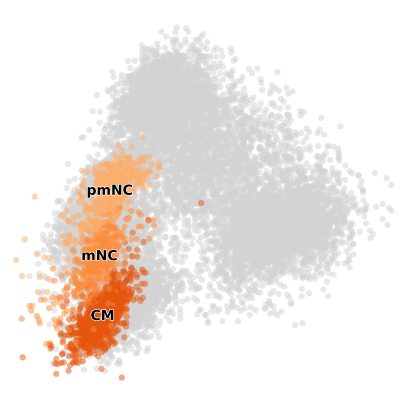

In [ ]:
palette = {
    'Premigratory Neural Crest'     : plt.cm.tab20c(6),
    'Migratory Neural Crest'        : plt.cm.tab20c(5),
    'Neuroglial Progenitors'        : plt.cm.tab20c(5),
    'Cranial Mesenchyme'            : plt.cm.tab20c(4)}

fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.embedding(adata_ref, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .5, frameon = False,
                show = False, ax = ax)
xlim = ax.get_xlim()
sc.pl.embedding(adata_ncc, 'X_mesencoder', dimensions = [1, 0],
                color = 'celltype', size = 80, alpha = .5,
                palette = palette,
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()
ax.set_xlim(xlim[0], xlim[1] - .35)

label_dict = {
    'Premigratory Neural Crest' : 'pmNC',
    'Migratory Neural Crest'    : 'mNC',
    'Neuroglial Progenitors'    : '',
    'Cranial Mesenchyme'        : 'CM'}

for label in ax.texts:
    _label_ = label.get_text()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])

# fn = os.path.join(pth_out, '.pdf')
# plt.savefig(fn, bbox_inches = 'tight')
plt.show()